# Exercise 1: Empirical Joint Distribution

In [ ]:
from pathlib import Path
import numpy as np

# find the CSV from the notebook or project directory
path = next(p for p in (Path("students.csv"), Path("3rd_Semester/UE_Probabilistic_Models/UE_Ex1/students.csv")) if p.is_file()) 

# read the observations, skipping the header
data = np.loadtxt(path, delimiter=",", skiprows=1, dtype=str)
indices = np.array([[int(value[1:]) for value in row] for row in data])

# convert category labels such as d0 and g1 to integers
indices[:, 2] -= 1

# allocate one count for each combination in axis order D,I,G,S,L
counts = np.zeros((2, 2, 3, 2, 2), dtype=int)

# count every observation, including repeated combinations
np.add.at(counts, tuple(indices.T), 1) 

# estimate each joint probability as its count divided by the number of observations
P_emp = counts / len(data)  
assert counts.sum() == len(data) and np.isclose(P_emp.sum(), 1) 

# check that every observation was counted and probabilities sum to one
# report sample size, array shape, and 48 minus one normalization constraint
print(f"Observations: {len(data)}; shape: {P_emp.shape}; free parameters: {P_emp.size - 1}")  
# display the complete empirical joint distribution
#print(P_emp)  


Observations: 1182; shape: (2, 2, 3, 2, 2); free parameters: 47


# Exercise 2: Probabilistic Queries

We use inference by enumeration on P_emp from Exercise 1: fix the observed categories, sum over the remaining variables, and divide by the probability of the evidence for conditional queries. Array axes are D,I,G,S,L; : selects all states of an axis and .sum() adds all selected entries. In particular, grade A (g1) has index 0.
The four queries in mathematical notation are:
1. $\widehat P_{\mathrm{emp}}(L=l_1)=\sum_{d,i,g,s}\widehat P_{\mathrm{emp}}(d,i,g,s,l_1)$.
2. $\widehat P_{\mathrm{emp}}(I=i_1\mid S=s_1)=\frac{\sum_{d,g,l}\widehat P_{\mathrm{emp}}(d,i_1,g,s_1,l)}{\sum_{d,i,g,l}\widehat P_{\mathrm{emp}}(d,i,g,s_1,l)}$.
3. $\widehat P_{\mathrm{emp}}(D=d_1\mid G=g_1)=\frac{\sum_{i,s,l}\widehat P_{\mathrm{emp}}(d_1,i,g_1,s,l)}{\sum_{d,i,s,l}\widehat P_{\mathrm{emp}}(d,i,g_1,s,l)}$.
4. $\widehat P_{\mathrm{emp}}(I=i_1\mid L=l_1,S=s_1)=\frac{\sum_{d,g}\widehat P_{\mathrm{emp}}(d,i_1,g,s_1,l_1)}{\sum_{d,i,g}\widehat P_{\mathrm{emp}}(d,i,g,s_1,l_1)}$.

In [ ]:
# P_emp shapes: D=2, I=2, G=3, S=2, L=2
# sum over D,I,G,S while fixing a strong letter L=l1
p1 = P_emp[:, :, :, :, 1].sum() 

# divide P(I=i1,S=s1) by P(S=s1), summing over all other variables
p2 = P_emp[:, 1, :, 1, :].sum() / P_emp[:, :, :, 1, :].sum()

# divide P(D=d1,G=g1) by P(G=g1); grade A uses index 0
p3 = P_emp[1, :, 0, :, :].sum() / P_emp[:, :, 0, :, :].sum()  

# sum over D,G to obtain P(I=i1,S=s1,L=l1)
numerator = P_emp[:, 1, :, 1, 1].sum()  

# sum over D,I,G to obtain P(S=s1,L=l1)
denominator = P_emp[:, :, :, 1, 1].sum()  

# normalize the joint probability by the probability of the evidence
p4 = numerator / denominator  

# the probability of a strong recommendation letter
print(f"P(L=l1) = {p1:.6f} ({p1:.2%})")  
# high interest given a high SAT score
print(f"P(I=i1 | S=s1) = {p2:.6f} ({p2:.2%})") 
# a hard course given an A grade
print(f"P(D=d1 | G=g1) = {p3:.6f} ({p3:.2%})") 
# high interest given a strong letter and a high SAT score
print(f"P(I=i1 | L=l1,S=s1) = {p4:.6f} ({p4:.2%})")  
# intermediate enumeration result
print(f"Last query: numerator = {numerator:.6f}; denominator = {denominator:.6f}")  


P(L=l1) = 0.483926 (48.39%)
P(I=i1 | S=s1) = 0.778243 (77.82%)
P(D=d1 | G=g1) = 0.047146 (4.71%)
P(I=i1 | L=l1,S=s1) = 0.888889 (88.89%)
Last query: numerator = 0.142132; denominator = 0.159898


## Intermediate steps for query 4 (expected slide content)

First enumerate the unobserved variables $D,G$ for the numerator:

$$A=\sum_{d,g}\widehat P_{\mathrm{emp}}(d,i_1,g,s_1,l_1)=\frac{168}{1182}=0.142132.$$

For the evidence probability, also enumerate $I$:

$$B=\sum_{d,i,g}\widehat P_{\mathrm{emp}}(d,i,g,s_1,l_1)=\frac{189}{1182}=0.159898.$$

Finally normalize:

$$\widehat P_{\mathrm{emp}}(I=i_1\mid L=l_1,S=s_1)=\frac{A}{B}=\frac{168/1182}{189/1182}=\frac{168}{189}=0.888889.$$

## Results for the solution slide

| Query | Probability | Percentage |
|---|---:|---:|
| $P(L=l_1)$ | 0.483926 | 48.39% |
| $P(I=i_1\mid S=s_1)$ | 0.778243 | 77.82% |
| $P(D=d_1\mid G=g_1)$ | 0.047146 | 4.71% |
| $P(I=i_1\mid L=l_1,S=s_1)$ | 0.888889 | 88.89% |

All probabilities in this table are empirical estimates from `P_emp`; displayed values are rounded.


# Exercise 3: Independence in the empirical distribution

We investigate all three claims using $\widehat P=\widehat P_{\mathrm{emp}}$. Each identity must hold for **every combination of states**:

$$D\perp I\iff\widehat P(d,i)=\widehat P(d)\widehat P(i).$$

$$S\perp\{D,G\}\mid I\iff\widehat P(d,g,s\mid i)=\widehat P(d,g\mid i)\widehat P(s\mid i).$$

$$L\perp\{D,I,S\}\mid G\iff\widehat P(d,i,s,l\mid g)=\widehat P(d,i,s\mid g)\widehat P(l\mid g).$$

All conditioning states (`i0,i1` and `g1,g2,g3`) occur, so all required conditional distributions are defined. We check independence from the **whole group** of variables, rather than checking its members separately.

The helper receives a two-dimensional table. Rows represent one variable or a group; columns represent the other variable. Dividing by the table sum normalizes the selected slice. `keepdims=True` preserves row and column dimensions for broadcasting. `reshape` combines adjacent axes without changing their entries.


In [ ]:
# compare a joint table P(X,Y) with the product of its two marginals
def deviation(table):
    # normalize the table to obtain the joint distribution, conditional on any fixed state
    joint = table / table.sum()
    # keep row and column dimensions so broadcasting produces all marginal products
    product = joint.sum(axis=1, keepdims=True) * joint.sum(axis=0, keepdims=True)
    # return the largest absolute difference across all combinations
    return np.abs(joint - product).max()

# sum over G,S,L to obtain the joint table for D and I
error1 = deviation(P_emp.sum(axis=(2, 3, 4)))
# for each I, sum over L and group D,G into six row states; columns represent S
error2 = max(deviation(P_emp[:, i, :, :, :].sum(axis=3).reshape(6, 2)) for i in range(2))
# for each G, group D,I,S into eight row states; columns represent L
error3 = max(deviation(P_emp[:, :, g, :, :].reshape(8, 2)) for g in range(3))
# collect the three claims and maximum deviations over all relevant states
results = [("D independent of I", error1), ("S independent of (D,G) given I", error2), ("L independent of (D,I,S) given G", error3)]
# iterate over the results to display each claim
for claim, error in results:
    # allow only floating-point rounding; this tolerance is not a statistical significance test
    print(f"{claim}: {error < 1e-12}; maximum absolute difference = {error:.8f}")


D independent of I: False; maximum absolute difference = 0.06496990
S independent of (D,G) given I: False; maximum absolute difference = 0.00822597
L independent of (D,I,S) given G: False; maximum absolute difference = 0.01088610


| Claim | Holds exactly in the empirical distribution? | Maximum absolute difference |
|---|---|---:|
| $D\perp I$ | No | 0.06496990 |
| $S\perp\{D,G\}\mid I$ | No | 0.00822597 |
| $L\perp\{D,I,S\}\mid G$ | No | 0.01088610 |

# Exercise 4: Factorisation and graphical model

From this task onward, **assume the three independence claims hold exactly**, as required by the assignment.

Start with the chain rule in the required order $D,I,G,S,L$:

$$P(D,I,G,S,L)=P(D)P(I\mid D)P(G\mid D,I)P(S\mid D,I,G)P(L\mid D,I,G,S).$$

Apply each assumption:

- $D\perp I$ gives $P(I\mid D)=P(I)$
- $S\perp\{D,G\}\mid I$ gives $P(S\mid D,I,G)=P(S\mid I)$
- $L\perp\{D,I,S\}\mid G$ gives $P(L\mid D,I,G,S)=P(L\mid G)$

Therefore

$$\boxed{P(D,I,G,S,L)=P(D)P(I)P(G\mid D,I)P(S\mid I)P(L\mid G).}$$

No stated assumption allows further removal of parents from $P(G\mid D,I)$.

## CPD shapes and non-redundant parameters (expected content)

We store **parent axes first and the child axis last**. Each parent configuration needs $r-1$ free parameters for $r$ child states.

| Factor | Axis order | Shape | Free parameters |
|---|---|---|---:|
| $P(D)$ | D | (2,) | $2-1=1$ |
| $P(I)$ | I | (2,) | $2-1=1$ |
| $P(G\mid D,I)$ | D,I,G | (2,2,3) | $2\cdot2\cdot(3-1)=8$ |
| $P(S\mid I)$ | I,S | (2,2) | $2\cdot(2-1)=2$ |
| $P(L\mid G)$ | G,L | (3,2) | $3\cdot(2-1)=3$ |

Full joint: $48-1=47$ free parameters. Factorised model: $1+1+8+2+3=15$. These are model dimensions; missing parent configurations can leave parameters undetermined by this particular sample.

## Directed graph

Edges: $D\to G$, $I\to G$, $I\to S$, $G\to L$.


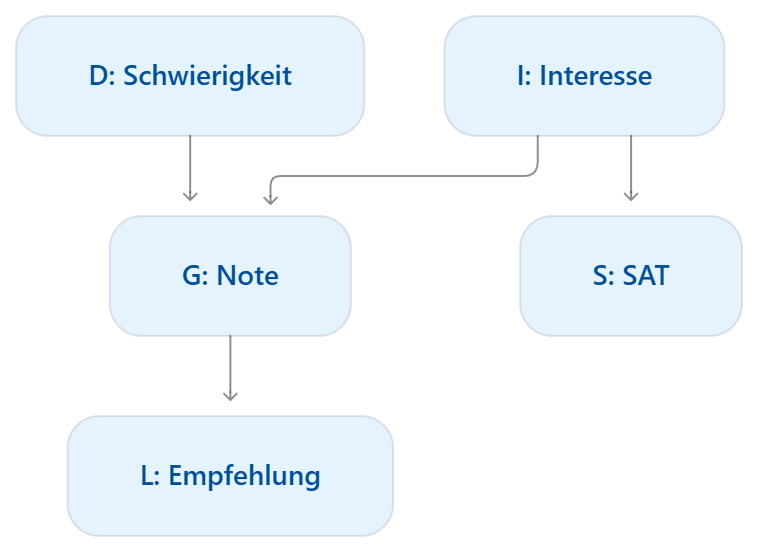

In [5]:
# count all joint states and remove the single normalization constraint
full_parameters = np.prod(P_emp.shape) - 1
# count free child probabilities separately for every parent configuration
model_parameters = (2 - 1) + (2 - 1) + 2 * 2 * (3 - 1) + 2 * (2 - 1) + 3 * (2 - 1)
# report the parameter counts for both models
print(f"Full joint: {full_parameters}; factorised model: {model_parameters}")


Full joint: 47; factorised model: 15


# Exercise 5: Model-based full joint distribution

Use **maximum-likelihood count ratios**:

$$\widehat P(d)=\frac{n(d)}N,\quad\widehat P(i)=\frac{n(i)}N,$$
$$\widehat P(g\mid d,i)=\frac{n(d,i,g)}{n(d,i)},\quad\widehat P(s\mid i)=\frac{n(i,s)}{n(i)},\quad\widehat P(l\mid g)=\frac{n(g,l)}{n(g)}.$$

Sum the full count array over irrelevant variables to obtain each marginal count table. Normalize over the child (last) axis. There is no smoothing for observed parent configurations.

**Missing parent configuration:** The data contain no observations with $(D=d_1,I=i_1)$. Therefore the data do not determine $P(G\mid d_1,i_1)$. We choose the uniform distribution $(1/3,1/3,1/3)$ as a symmetric, normalized fallback. Every normalized choice for this unobserved parent configuration gives the same data likelihood. All parent states for the other CPDs occur.

The choice matters: the model assumes $D\perp I$, so it gives positive mass to $(d_1,i_1)$ even though this pair is unobserved. Different fallback CPDs can change the model joint in this region.

Construct every entry by multiplication:

$$\widehat P_{\mathrm{model}}(d,i,g,s,l)=\widehat P(d)\widehat P(i)\widehat P(g\mid d,i)\widehat P(s\mid i)\widehat P(l\mid g).$$


In [ ]:
# normalize each child distribution along the last axis
def normalize(table):
    # count observations for each parent configuration while keeping the child axis
    total = table.sum(axis=-1, keepdims=True)
    # divide where counts are positive and otherwise keep a uniform child distribution
    return np.divide(table, total, out=np.full(table.shape, 1 / table.shape[-1]), where=total > 0)

# estimate difficulty by summing over all other variables
pD = normalize(counts.sum(axis=(1, 2, 3, 4)))

# estimate interest by summing over all other variables
pI = normalize(counts.sum(axis=(0, 2, 3, 4)))

# estimate grade given difficulty and interest by summing over SAT and letter
pG = normalize(counts.sum(axis=(3, 4)))

# estimate SAT given interest by summing over difficulty, grade and letter
pS = normalize(counts.sum(axis=(0, 2, 4)))

# estimate letter given grade by summing over difficulty, interest and SAT
pL = normalize(counts.sum(axis=(0, 1, 3)))

# count missing parent configurations for grade, SAT and letter
missing = [int((table.sum(axis=-1) == 0).sum()) for table in (counts.sum(axis=(3, 4)), counts.sum(axis=(0, 2, 4)), counts.sum(axis=(0, 1, 3)))]

# report how many uniform fallback distributions were needed
print(f"Missing parent configurations for G, S, L: {missing}")

# allocate the joint model array in axis order D,I,G,S,L
P_model = np.zeros_like(P_emp)

# visit every combination of the five variables
for d, i, g, s, l in np.ndindex(P_model.shape):
    # multiply the five local probabilities for this combination
    P_model[d, i, g, s, l] = pD[d] * pI[i] * pG[d, i, g] * pS[i, s] * pL[g, l]
    
# check nonnegative entries and normalization of the full distribution
assert np.all(P_model >= 0) and np.isclose(P_model.sum(), 1)
# iterate over all estimated local probability tables
for name, table in [("P(D)", pD), ("P(I)", pI), ("P(G|D,I)", pG), ("P(S|I)", pS), ("P(L|G)", pL)]:
    # display each table with six decimal places
    print(f"{name}:\n{np.array2string(table, precision=6)}")


Missing parent configurations for G, S, L: [1, 0, 0]
P(D):
[0.675973 0.324027]
P(I):
[0.799492 0.200508]
P(G|D,I):
[[[0.291815 0.3879   0.320285]
  [0.92827  0.07173  0.      ]]

 [[0.049608 0.234987 0.715405]
  [0.333333 0.333333 0.333333]]]
P(S|I):
[[0.943915 0.056085]
 [0.21519  0.78481 ]]
P(L|G):
[[0.064516 0.935484]
 [0.409231 0.590769]
 [0.993392 0.006608]]


## Tables for the solution slide (expected content)

The output above contains every CPD. Root entries follow `d0,d1` and `i0,i1`. In `pG`, the first two axes select D and I, and the last lists `g1,g2,g3`. Rows of `pS` select `i0,i1`, with columns `s0,s1`. Rows of `pL` select `g1,g2,g3`, with columns `l0,l1`.

For a compact slide, use `P(S|I)` and `P(L|G)` as selected tables, give the count-ratio formulas and joint multiplication rule, and state the uniform fallback for `P(G|d1,i1)`. The output `[1, 0, 0]` confirms one missing parent configuration for G and none for S or L.


# Exercise 6: Compare the two distributions

**Why can the distributions differ?** The empirical distribution stores relative frequencies of complete observation patterns. The model combines local tables under exact independence restrictions. These restrictions reduce the model dimension from 47 to 15 and do not hold exactly in the empirical data. Therefore the two estimates need not coincide despite using the same observations. Here, the model additionally assigns positive mass to the unobserved pair $(d_1,i_1)$; the grade distribution there depends on our documented fallback.

Repeat all independence checks from Exercise 3 with `P_model`. Also report the largest cell difference and total variation distance:

$$\operatorname{TV}(\widehat P_{\mathrm{emp}},\widehat P_{\mathrm{model}})=\frac12\sum_{d,i,g,s,l}|\widehat P_{\mathrm{emp}}(d,i,g,s,l)-\widehat P_{\mathrm{model}}(d,i,g,s,l)|.$$


In [8]:
# compare both full joint distributions cell by cell
print(f"Maximum difference: {np.abs(P_emp - P_model).max():.8f}; total variation: {0.5 * np.abs(P_emp - P_model).sum():.8f}")
# repeat the difficulty-interest independence check with the model
model_error1 = deviation(P_model.sum(axis=(2, 3, 4)))
# repeat the conditional SAT check for both interest states
model_error2 = max(deviation(P_model[:, i, :, :, :].sum(axis=3).reshape(6, 2)) for i in range(2))
# repeat the conditional letter check for all three grades
model_error3 = max(deviation(P_model[:, :, g, :, :].reshape(8, 2)) for g in range(3))
# pair empirical and model deviations for each claim
comparison = [("D independent of I", error1, model_error1), ("S independent of (D,G) given I", error2, model_error2), ("L independent of (D,I,S) given G", error3, model_error3)]
# iterate over all three comparisons
for claim, empirical, model in comparison:
    # report deviations and whether the model satisfies independence within rounding tolerance
    print(f"{claim}: empirical={empirical:.8f}; model={model:.2e}; model independent={model < 1e-12}")


Maximum difference: 0.04533959; total variation: 0.13539138
D independent of I: empirical=0.06496990; model=2.78e-17; model independent=True
S independent of (D,G) given I: empirical=0.00822597; model=1.11e-16; model independent=True
L independent of (D,I,S) given G: empirical=0.01088610; model=1.67e-16; model independent=True


## Results for the solution slide (expected content)

| Claim | Empirical maximum deviation | Model maximum deviation | Model claim holds? |
|---|---:|---:|---|
| D independent of I | 0.06496990 | 2.78e-17 | Yes |
| S independent of (D,G) given I | 0.00822597 | 1.11e-16 | Yes |
| L independent of (D,I,S) given G | 0.01088610 | 1.67e-16 | Yes |

Maximum absolute difference: **0.04533959**. Total variation: **0.13539138**.

All three independence claims now hold up to floating-point rounding, because they are built into the factorisation. All three failed as exact identities in the empirical distribution. This change follows from the assumptions; it is not independent evidence that they hold in the population.
